# Week 4 - Part C: part-to-whole legality, and the pie-ranking experiment

Q1 tests the three slide-32 conditions in code. Q2-Q3 are an experiment on a **real reader**: the stimuli and the timing harness are below, and the scoring cell reads whatever is in `pie_ranking_results.csv`. Nothing in the results file is typed in by hand.

In [1]:
import sys
import time
import argparse
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

try:
    ROOT = Path(__file__).resolve().parents[1]
    IN_NOTEBOOK = False
except NameError:
    ROOT = Path.cwd()
    IN_NOTEBOOK = True
sys.path.insert(0, str(ROOT))


def show():
    """Inline in the notebook; as a script just close the figure (the PNG is already saved)."""
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close("all")


import tslib
from vizlib import PALETTE, save_fig, style_defaults

DATA = ROOT / "data"
CHARTS = ROOT / "charts"
SUB = ROOT / "submission"
for p in (CHARTS, SUB):
    p.mkdir(exist_ok=True)
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK, SOFT = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"], PALETTE["ink_soft"]
RESULTS = SUB / "pie_ranking_results.csv"

## Q1 · The three conditions, tested in code (3 marks)
Exclusive parts · a meaningful whole · the share is actually the question.

### (a) The four `touch_*` columns of case 8

In [2]:
c8 = pd.read_csv(DATA / "case08_channel_attrib.csv")
touch = [c for c in c8.columns if c.startswith("touch_")]
ex8 = tslib.exclusivity_check(c8, touch)
print(ex8)
print("assert shares sum to 100:", abs(ex8["sum_pct"] - 100) < 1e-6)

{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}
assert shares sum to 100: False


- **Exclusive?** No. 1,105 customers (27.6%) are in two or more columns and the shares sum to 131%.
- **Meaningful whole?** No. "All touches" is not a population of anything, since a customer counts once per channel.
- **Share is the question?** No. The question is reach ("what % of customers did each channel touch?"), and that is four separate out-of-100 numbers.
- **Verdict: no pie, no stacked bar.** Separate bars, each labelled "% of customers touched", are fine as long as nobody calls them shares (the redesign in Part A case 8 also shows the exclusive split that does sum to 100%).

### (b) The eight rows of `shares_eight.csv`

In [3]:
sh = pd.read_csv(DATA / "shares_eight.csv")
print(sh)
total8 = sh.share_pct.sum()
print(f"sum = {total8}")
assert abs(total8 - 100) < 1e-6

cat = pd.read_csv(DATA / "revenue_catalogue.csv")
cat = cat.drop(index=cat.index[(cat.sku == "SKU-0127") & (cat.subcategory == "Wearables")])   # Part D's duplicate rule
parents = cat.groupby("sku").subcategory.nunique()
print(f"SKUs in more than one sub-category (after Part D's de-dup): {(parents > 1).sum()} of {len(parents)}")
print(f"the eight sub-categories cover the whole catalogue: {sorted(sh.subcategory) == sorted(cat.subcategory.unique())}")

  slice  subcategory  share_pct
0     A       Phones       24.6
1     B      Laptops       18.4
2     C        Audio       15.0
3     D    Wearables        9.2
4     E      Cameras        6.1
5     F       Drones        2.4
6     G     Footwear       11.2
7     H  Accessories       13.1
sum = 100.0
SKUs in more than one sub-category (after Part D's de-dup): 0 of 344
the eight sub-categories cover the whole catalogue: True


- **Exclusive?** Yes, every SKU sits in exactly one sub-category once Part D's duplicate SKU is removed, and the shares sum to exactly 100.
- **Meaningful whole?** Yes, the eight are the entire catalogue's net revenue for the period.
- **Share is the question?** Yes, "how is revenue split across the catalogue" is a mix question.
- **Verdict: a pie is *legal*, but a bar chart is better.** Eight slices with C, H and G within four points of each other is exactly where angle judgments fail (Week 2 channel ranking: position > length > angle > area). Q2 tests that.

### (c) Premium vs other revenue, 2025Q4

In [4]:
c9 = pd.read_csv(DATA / "case09_premium_share.csv")
q4 = c9[c9.quarter == "2025Q4"].iloc[0]
parts = pd.Series({"premium": q4.premium_revenue_pkr_m, "other": q4.total_revenue_pkr_m - q4.premium_revenue_pkr_m})
pct = parts / q4.total_revenue_pkr_m * 100
print(parts.to_dict(), pct.round(1).to_dict())
assert abs(pct.sum() - 100) < 1e-6 and (parts >= 0).all()
print(f"premium revenue 2024Q1 -> 2025Q4: {c9.premium_revenue_pkr_m.iloc[0]} -> {q4.premium_revenue_pkr_m} | total {c9.total_revenue_pkr_m.iloc[0]} -> {q4.total_revenue_pkr_m}")

{'premium': 228.0, 'other': 372.0} {'premium': 38.0, 'other': 62.0}
premium revenue 2024Q1 -> 2025Q4: 240.0 -> 228.0 | total 1000.0 -> 600.0


- **Exclusive?** Yes, by construction: other = total − premium, both non-negative.
- **Meaningful whole?** Yes, the quarter's total revenue.
- **Share is the question?** Only if the question is "what was the Q4 mix" (38 / 62). The claim being made is about premium *growing*, and that's a question about absolute revenue, which fell 5%.
- **Verdict:** for the Q4 mix alone, a two-slice pie (or one stacked bar) is legal and readable, since two parts is the one case where angle works fine. For the "record" claim, **neither**: the honest chart is the absolute revenue lines from Part A case 9.

## Q2 · The stimuli

true order (largest first): ABCHGDEF


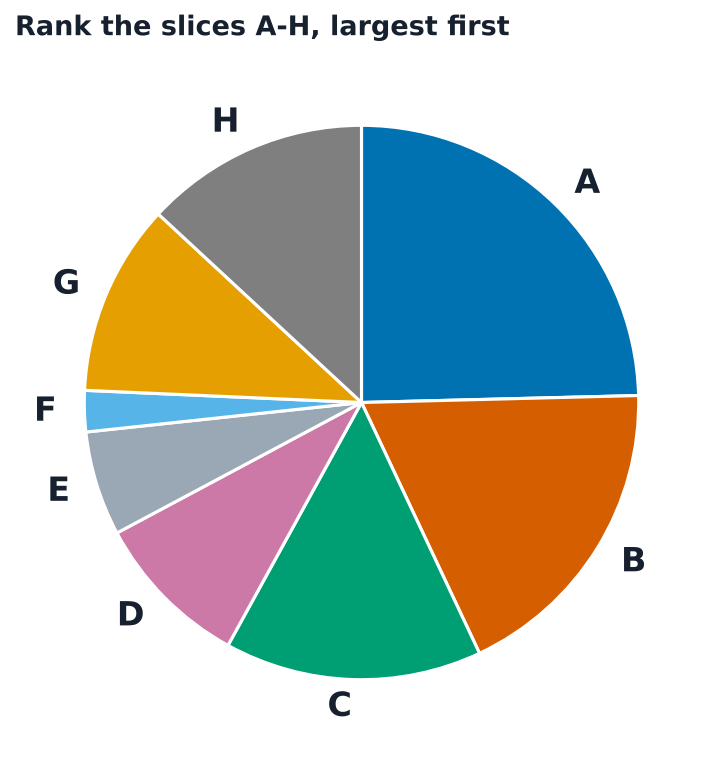

In [5]:
TRUE_ORDER = "".join(sh.sort_values("share_pct", ascending=False).slice)
print("true order (largest first):", TRUE_ORDER)

def pie_stimulus():
    fig, ax = plt.subplots(figsize=(6, 6))
    cols = [BLUE, ORANGE, GREEN, PINK, GREY, "#56B4E9", "#E69F00", "#7F7F7F"]
    ax.pie(sh.share_pct, labels=sh.slice, colors=cols, startangle=90, counterclock=False,
           wedgeprops=dict(edgecolor="white", linewidth=1.5), textprops=dict(fontsize=16, fontweight="bold"))
    ax.set_title("Rank the slices A-H, largest first", fontsize=13)
    return fig

def bar_stimulus():
    srt = sh.sort_values("share_pct")
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.barh(srt.slice, srt.share_pct, color=BLUE)
    ax.set_xticks([])                       # no numbers on either stimulus
    ax.tick_params(axis="y", labelsize=14)
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
    ax.set_title("Rank the bars A-H, largest first", fontsize=13)
    return fig

fig = pie_stimulus()
fig.savefig(SUB / "partC_stimulus_pie.png", dpi=300, bbox_inches="tight", facecolor="white")
show()

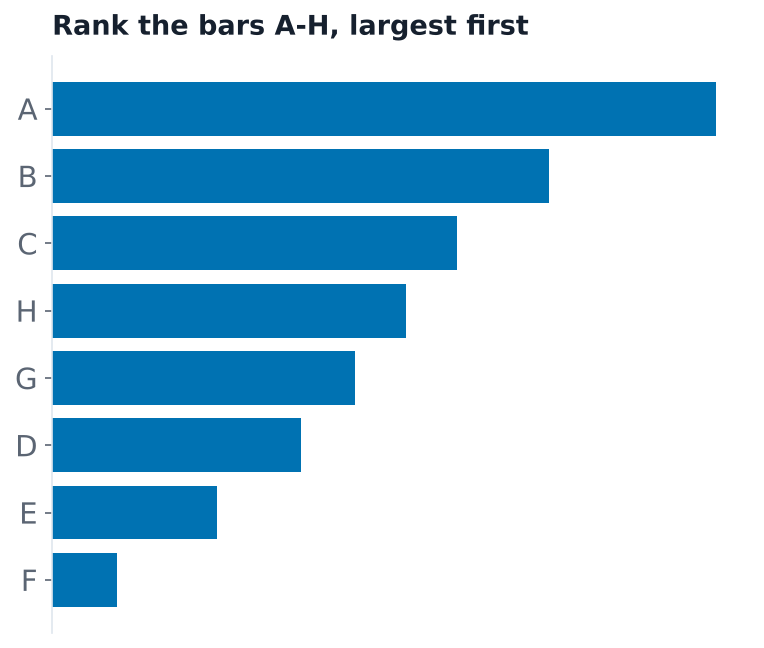

In [6]:
fig = bar_stimulus()
fig.savefig(SUB / "partC_stimulus_bars.png", dpi=300, bbox_inches="tight", facecolor="white")
show()

**The stimuli.** Same eight shares in both. The pie keeps the file's order (A-H clockwise from 12 o'clock) and the bars are sorted. Neither has a single number on it, so the reader can only use angle/area on one and length/position on the other.

## Q2 · The timing harness
Run this with one real person who has **not** seen the shares. Set `RUN_EXPERIMENT = True` and the reader's name, run the cell, and they type the eight letters in their order into the box (the reader should only see the figures, not this notebook). Each figure is shown, the clock starts, and it stops when they press Enter. Or from a terminal: `python submission/partC_shares.py --run "Reader name"`.

In [7]:
RUN_EXPERIMENT = False          # set True only when a real reader is sitting in front of the screen
READER = "reader_1"             # their name or initials

def ask(fig, stimulus, reader):
    if IN_NOTEBOOK:
        from IPython.display import display, clear_output
        display(fig)
    else:
        plt.show(block=False)
        plt.pause(0.5)
    t0 = time.perf_counter()
    answer = input(f"[{stimulus}] type the letters largest first, then Enter: ")
    secs = time.perf_counter() - t0
    plt.close(fig)
    if IN_NOTEBOOK:
        clear_output()
    order = "".join(ch for ch in answer.upper() if ch in "ABCDEFGH")
    return {"reader": reader, "stimulus": stimulus, "order": order, "seconds": round(secs, 2),
            "recorded_at": datetime.now().isoformat(timespec="seconds")}

def run_reader(reader):
    rows = [ask(pie_stimulus(), "pie", reader), ask(bar_stimulus(), "bars", reader)]
    new = pd.DataFrame(rows)
    if RESULTS.exists():
        new = pd.concat([pd.read_csv(RESULTS), new], ignore_index=True)
    new.to_csv(RESULTS, index=False)
    print(f"saved {len(rows)} rows for {reader} -> {RESULTS.name}")

if RUN_EXPERIMENT:
    run_reader(READER)
else:
    print("RUN_EXPERIMENT is False - no reader timed in this run.")

RUN_EXPERIMENT is False - no reader timed in this run.


## Q3 · Score it (2 marks)
Errors = letters not in their true rank position. The deck predicts readers get the top two and the bottom one right and mix up the middle, because **C (15.0%), H (13.1%) and G (11.2%)** are only about two points apart.

In [8]:
def score(order, truth=TRUE_ORDER):
    wrong = [i + 1 for i, (o, t) in enumerate(zip(order.ljust(8, "?"), truth)) if o != t]
    return len(wrong), wrong

if RESULTS.exists() and len(pd.read_csv(RESULTS)):
    res = pd.read_csv(RESULTS)
    res["n_wrong"], res["wrong_ranks"] = zip(*res.order.astype(str).map(score))
    res["top2_right"] = res.order.astype(str).str[:2] == TRUE_ORDER[:2]
    res["last_right"] = res.order.astype(str).str[-1:] == TRUE_ORDER[-1]
    print(res[["reader", "stimulus", "order", "seconds", "n_wrong", "wrong_ranks", "top2_right", "last_right"]].to_string(index=False))
    for reader, g in res.groupby("reader"):
        p, b = g[g.stimulus == "pie"].iloc[-1], g[g.stimulus == "bars"].iloc[-1]
        mid = [r for r in p.wrong_ranks if 3 <= r <= 7]
        print(f"\n{reader}: pie {p.n_wrong} wrong in {p.seconds:.1f}s, bars {b.n_wrong} wrong in {b.seconds:.1f}s "
              f"({p.seconds / b.seconds:.1f}x slower on the pie). Pie errors at ranks {p.wrong_ranks} "
              f"-> {len(mid)} of {p.n_wrong} in the middle (ranks 3-7). Prediction "
              f"{'held' if p.top2_right and p.last_right and len(mid) == p.n_wrong else 'did not fully hold'}.")
else:
    print("No reader has been run yet - pie_ranking_results.csv is empty, so there is nothing to score.")
    print("Run the harness above with one real person, then re-run this cell.")

No reader has been run yet - pie_ranking_results.csv is empty, so there is nothing to score.
Run the harness above with one real person, then re-run this cell.


**How to read the result.** The cell above prints the reader's order, seconds, how many letters were misplaced and at which ranks, for both stimuli, and whether the deck's prediction held. One reader is one reader: it can show *whether* a person struggled with the middle of the pie, but it can't estimate how often people do, or say anything about readers in general. It's a demonstration, not an experiment, and if my reader disagrees with the deck I'll report it as it came out.

## Q4 · My rule (1 mark)

**I will only draw a pie when the parts are exclusive and sum to a real whole, there are at most two or three of them, and the question is "roughly what fraction is this", never "which is bigger"; for everything else I use sorted bars.**

In [9]:
if __name__ == "__main__" and not IN_NOTEBOOK:
    ap = argparse.ArgumentParser()
    ap.add_argument("--run", metavar="READER", help="time one real reader on both stimuli")
    args, _ = ap.parse_known_args()
    if args.run:
        RUN_EXPERIMENT = True
        run_reader(args.run)